*Do not delete this style setting*

In [27]:
%%html
<style>
table {float:left}
</style>

# Session 2:<br>A Simple Quantum Estimator

<table>
    <tr><td><strong>Aim:</strong></td>
        <td>To explore the creation and use of a simple quantum estimator in <strong>PennyLane</strong><br>
            Note that "simplicity" is only in data and the model structure - not in the approach!</td></tr>
    <tr><td><strong>Author:</strong></td>
        <td>Jacob L. Cybulski (<a href="https://jacobcybulski.com/" target="_blank">website</a>),
            <em>Enquanted</em></td></tr>
    <tr><td><strong>Release:</strong></td>
        <td>April 2025</td></tr>
    <tr><td><strong>Updated:</strong></td>
        <td>October 2026</td></tr>
    <tr><td><strong>Datasets:</strong></td>
        <td>We will use the following two data set generators from sklearn (code below):<br>
            <ol><li>from sklearn.datasets import <strong><em>make_regression</em></strong> (Workshop)</li>
                <li>from sklearn.datasets import <strong><em>make_swiss_roll</em></strong> or <br>
                    from UCI repository download <strong><em><a href="https://archive.ics.uci.edu/dataset/477/real+estate+valuation+data+set" target="_blank">Real Estate Valuations</a></em></strong> dataset<br>(requires: ucimlrepo)</li>
            </ol></td></tr>
    <tr><td><strong>Tasks:</strong></td>
        <td>40 minutes (unfinished tasks go to self-directed "challenges")</td></tr>
    <tr>
        <td></td>
        <td>Perform the following tasks<br>(record your observations at end of this notebook):<br><ol>
            <li>Initially use the <strong><em>Regression</em></strong> dataset 1 (as provided).<br>
                Follow the instructor demonstration to step through the code.<br>
                - consider changing qubit type and diff-method to reduce training time.</li>
            <li>Can you improve the selected model by:<br>
                - changing entangling methods (basic_ent = False/True) ?<br>
                - changing the number of qubits/wires and layers ?<br>
                - changing the number of training epochs ?<br>
                - changing the optimiser and/or its parameters ? (e.g. learning rate)<br>
                Which of these changes had the greatest impact on performance?</li>
            <li>Change data encoding by increasing the encoding margin.<br>
                What was the impact of your change? Why do you think it happened ?</li>
            <li>Calculate testing MSE and R2 scores.<br>
                Follow the example of calculating training R2.</li>
            <li>Create a plot of residuals for training and test predictions.<br>
                Note that residuals are (expected-predicted) values.<br>
                Can you provide better diagnostic charts?</li>
            <li>Test if global cost (measuring all qubits) could improve<br>
                the result of a model with a local cost (measuring one qubit).<br>
                - Hint calculate a tensor product of Z observables.</li>
            <li>Reflect on this session.</li>
        </ol></td>
    </tr>
    <tr>
        <td><strong>Challenge<br>Tasks:</strong></td>
        <td>Perform the following tasks in your own time:<br/>
        <ol style="list-style-type: upper-alpha;">
            <li>Complete the unfinished tasks.</li>
            <li>Change the model by incorporating the reuploading ansatz (see Session 1).</li>
            <li>Create a more insightful visualisation of residuals (research).</li>
            <li>Apply your completed model to either of the following data sets:<br>
                <strong><em>Real Estate Valuations</em></strong> or <strong><em>Swiss Roll</em></strong> (data set 2)<br> 
                - see examples at the end of the notebook<br>
            </li>
        </ol>
        </td>
    </tr>
    <tr><td><strong>References:</strong></td>
        <td><a href="https://www.youtube.com/watch?v=42aa-Ve5WmI" target="_blank">
            Catalina Albornoz, "Optimizing a quantum circuit with PennyLane",<br>PennyLane Tutorial, YouTube Video, Sept 12, 2023.</a></td>
    </tr>
    <tr><td><strong>License:</strong></td>
        <td>This project is licensed under the
            <a href="https://www.gnu.org/licenses/gpl-3.0.en.html" target="_blank">GNU General Public License v3</a></td></tr>
    <tr><td><strong>Changes:</strong></td>
        <td>All significant changes to this code must be recorded in this notebook</td></tr>
</table>

## Libraries

In [28]:
import sys
sys.path.append('.')
sys.path.append('..')
sys.path

['c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\python312.zip',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\DLLs',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312',
 '',
 'C:\\Users\\codeg\\AppData\\Roaming\\Python\\Python312\\site-packages',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\win32',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\win32\\lib',
 'c:\\Users\\codeg\\AppData\\Local\\Programs\\Python\\Python312\\Lib\\site-packages\\pythonwin',
 '.',
 '..',
 '.',
 '..']

In [29]:
### General libraries

import os
import math
import time
import copy
import numpy as nnp # if wanted to use standard numpy
import pandas as pd
from IPython.display import clear_output

import matplotlib.pyplot as plt
from matplotlib import set_loglevel
set_loglevel("warning")

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

In [30]:
### Import utilities
from utilities import *

In [31]:
### Import PennyLane
import pennylane as qml
from pennylane import numpy as np # redefined numpy
import torch # for Linux with 'lightning-quit' and diff_method='adjoint'

import plotly.express as px
from sklearn.datasets import make_regression
from sklearn.metrics import r2_score, mean_squared_error

---

## <font color="blue">Data preparation</font>
<font color="LightCoral">Task 1: Follow the instructor demonstration to step through the code.</font>

### Data set in its original form

In [32]:
import plotly.io as pio
# The following may preserve the chart on saving
# pio.renderers.default = 'jupyterlab' # or 'notebook'

np.random.seed(42)  # For reproducibility
data_seed = 42
n_samples = 100
n_features = 2

# Generate synthetic regression data
X_raw, y_raw = make_regression(
    n_samples=n_samples,
    n_features=n_features, 
    noise=5.0,
    random_state=data_seed
)
y_raw = y_raw.reshape((y_raw.shape[0], 1))

# Create an interactive 3D scatter plot, of the first two columns
fig = px.scatter_3d(x=X_raw[:, 0], y=X_raw[:, 1], z=y_raw[:, 0], 
                    title='Interactive 3D Scatter Plot',
                    labels={'x': 'Feature x', 
                            'y': 'Feature y', 
                            'z': 'Target'})
mrg = dict(l = 50, r = 50, b = 50, t = 50, pad = 10)
fig.update_traces(marker=dict(size=3, color='CornflowerBlue', symbol='circle'))
fig.update_layout(width=600, height=600, margin = mrg, paper_bgcolor = 'whitesmoke')
fig.show()

---

## <font color="blue">Model development</font>

### Model and training configuration
<font color="LightCoral">Task 2: Experiment with the model size and training hyper-parameters.</font>

- <font color="LightCoral">Change basic to strong entangling method (basic_ent = False)</font>
- <font color="LightCoral">Change the number of qubits/wires _**n_wires**_ (what happens)</font>
- <font color="LightCoral">Change the number of layers _**n_layers**_</font>
- <font color="LightCoral">Change the number of training epochs _**epochs**_</font>

<font color="LightCoral">Task 3: Increase the encoding margin.</font>

- <font color="LightCoral">Change the value of _**x_angle_margin**_ to 0.5.</font>
- <font color="LightCoral">What is the impact of this change? Why?</font>

In [33]:
### Data params used in scaling
#   Encoded values to be scaled to range (0..pi)
#   Optionally, margins can be left out on the value boundaries
x_angle_margin = 0.1
x_angle_min = 0+x_angle_margin
x_angle_max = np.pi-x_angle_margin

### Architectural parameters
n_wires = 2 # n_features
n_layers = 5
basic_ent = True
wires = list(range(n_wires))

### Training hyper-parameters
epochs = 50 # 20 # 50 (preferred) # 100 # 300 (long wait)
prompt_fract = 0.05 # Fraction of results shown in training
shots = None # Theoretical results will be computed
seed = 2025

### Prepare data for the quantum estimator

In [34]:
### Standardise X values to the range 0..pi
from sklearn.preprocessing import StandardScaler, MinMaxScaler
X_scaler = MinMaxScaler(feature_range=(x_angle_min, x_angle_max)) 
X_scaled = X_scaler.fit_transform(X_raw)
y_scaler = MinMaxScaler(feature_range=(0, 1))
y_scaled = y_scaler.fit_transform(y_raw)

In [35]:
### Create data partitions
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, 
                                                    test_size=0.33, random_state=seed, shuffle=False)
print(f'Shapes: X_train={X_train.shape}, X_test={X_test.shape}, y_train={y_train.shape}, y_test={y_test.shape}')

Shapes: X_train=(67, 2), X_test=(33, 2), y_train=(67, 1), y_test=(33, 1)


In [36]:
### Change the data format to tensors
X_train_tens = qml.numpy.tensor(np.array(X_train), requires_grad=False)
y_train_tens = qml.numpy.tensor(np.array(y_train), requires_grad=False)
X_test_tens  = qml.numpy.tensor(np.array(X_test), requires_grad=False)
y_test_tens  = qml.numpy.tensor(np.array(y_test), requires_grad=False)

## Loss and cost function

In [37]:
### Our own gradient-friendly loss function
#   Note for Mac users
#      It seems that when we calculate loss = (l - p) ** 2
#      on MacOS we get a strange fatal error!
def mse_cost(targets, predictions):
    cost = 0
    for l, p in zip(targets, predictions):
        loss = (p - l) ** 2
        cost = cost + loss
    cost = cost / len(targets)
    return cost

### The cost function generator
def cost_fun_gen(model, cost_fun):
    def _cost_fun(params, inputs, targets):
        nonlocal model, cost_fun
        preds = [model(params, x) for x in inputs]
        return cost_fun(targets, preds)
    return _cost_fun

## PennyLane quantum linear model
*If you'd like to accelerate your computation, change the qubit type!<br>
But then you will also have to change the diff_method!*

In [38]:
### Define default device
sim = 'default.qubit' # default.qubit lightning.qubit lightning.gpu
dev = qml.device(sim, wires=n_wires, shots=shots)

print(f'Device to be used:  {sim}\n')

Device to be used:  default.qubit



<font color="CornflowerBlue">PennyLane model optimisation relies on the concept of <strong><em>differentiable programming</em></strong>.<br>
This means that every model component must be a function or its equivalent (e.g. matrix or circuit).<br>
Quantum models presented below are implemented in terms of pure functions.<br>
Such functions do not reference any global variables but take advantage of the <em><strong>nested</strong> or <strong>composite functions</strong></em>.<br>
The higher level function sets the variable scope for the inner function, which is retained.<br>
Optimisation of such models is done by using their function derivatives, which is achieved by the <strong><em>chain rule</em></strong>.<br>
PennyLane has many functions implemented in this way, e.g. functions responsible for circuit drawing.</font>

*Note that the following model has the flexibility of using either basic or strong qubit entanglement.*

In [39]:
### Define a quantum linear model functionally
### This is the PennyLane style of doing things
def qlinear(n_wires, scaler=1.0, basic=False):
    
    def _qlinear(weights, inputs):
        nonlocal n_wires, scaler, basic
        data_wires = list(range(n_wires))
        scaled_inputs = inputs * scaler

        # Standard angle encoding block
        qml.AngleEmbedding(scaled_inputs, wires=data_wires)  

        # Ansatz with optional basic or strong entangling block
        if basic:
            qml.BasicEntanglerLayers(weights, wires=data_wires, rotation=qml.RY)
        else:
            qml.StronglyEntanglingLayers(weights, wires=data_wires)
        return qml.expval(qml.PauliZ(0))
        
    return _qlinear

<font color="CornflowerBlue">When we create a complex model, we also need to define a method of calculating its parameters shape.<br>
By turning this method into a function, which could be used wherever is needed, we ensure consistency of shape calculation.<br>
For some basic circuit "patterns", PennyLane provides shape calculating helper functions (as used in here).</font>

In [40]:
### Check the model shape
### This is defined so that we could select and check the shape in one place
def qlinear_shape(n_wires, n_layers=1, basic=False):
    if basic:
        shape = qml.BasicEntanglerLayers.shape(n_layers=n_layers, n_wires=n_wires)
    else:
        shape = qml.StronglyEntanglingLayers.shape(n_layers=n_layers, n_wires=n_wires)
    return shape

<font color="CornflowerBlue">Note that in contrast with the Session 1 model, we are not using the function decoration to create a model QNode (circuit),<br>
but instead we create the QNode step by step.</font>

*If you'd like to accelerate your computation and changed the qubit type!<br>
You will also have to change the diff_method!*

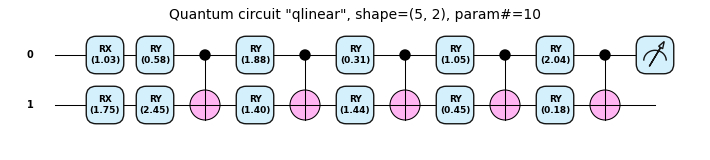

In [41]:
### Create a quantum linear model

# Prepare the quantum linear model and then its qnode (circuit)
qmodel = qlinear(n_wires, basic=basic_ent)
qlinear_model = qml.QNode(qmodel, device=dev, diff_method='parameter-shift')
shape = qlinear_shape(n_wires, n_layers=n_layers, basic=basic_ent)

# Plot the model circuit (needs weights and some input)
test_params = np.random.uniform(high=np.pi, size=shape, requires_grad=True)
draw_circuit(qlinear_model, scale=0.5, 
             title=f'Quantum circuit "qlinear", shape={shape}, param#={np.prod(shape)}', level='device') \
    (test_params, X_train_tens[0]) # level='device'/'gradient'

In [42]:
### Test the model
print(f'\nQM weights: {np.prod(shape)}, Epochs: {epochs}')
print(f'\nTest results: {qlinear_model(test_params, X_train_tens[0:5])}\n')


QM weights: 10, Epochs: 50

Test results: [-0.17848355  0.4114703  -0.79011875 -0.0024597  -0.10829291]



## Creation and training of the linear model

In [43]:
### Set the random seed
np.random.seed(seed)

### Select one of the following optimisers built into PennyLane
# opt = qml.GradientDescentOptimizer(stepsize=0.5)
# opt = qml.RMSPropOptimizer(stepsize=0.1, decay=0.7, eps=1e-08)
# opt = qml.NesterovMomentumOptimizer(stepsize=0.5)
# opt = RCDOptimizer(h=0.1)
opt = qml.AdamOptimizer(stepsize=0.5)

### Define the cost function
cost_fun = cost_fun_gen(qlinear_model, mse_cost)

### Initialise the model weights / parameters
params = np.random.uniform(high=np.pi, size=shape, requires_grad=True)

### Training loop
hist_cost = []
hist_params = []
prompt_fract = 0.1
start_time = time.time() 
for iter in range(epochs):
    params, cost = opt.step_and_cost(lambda p: cost_fun(p, X_train_tens, y_train_tens), params)
    hist_cost.append(cost.item())
    hist_params.append(params)
    elapsed_time = time.time()-start_time
    if (prompt_fract == 0) or (iter % int(prompt_fract*epochs) == 0):
        print(f'Iter: {iter:03d} ({int(elapsed_time):03d} sec) cost={np.round(cost, 6)}')

### Print the training summary
train_mse_hist = hist_cost
train_min_mse = np.min(train_mse_hist)
train_min_mse_iter = np.argmin(train_mse_hist)
print(f'\nTraining completed: epochs={epochs}, '+\
      f'min cost={np.round(train_min_mse, 6)} @ {train_min_mse_iter}, '+\
      f'time={int(elapsed_time):03d} secs\n')

Iter: 000 (002 sec) cost=[0.528581]
Iter: 005 (014 sec) cost=[0.123771]
Iter: 010 (045 sec) cost=[0.061866]
Iter: 015 (082 sec) cost=[0.036531]
Iter: 020 (096 sec) cost=[0.02387]
Iter: 025 (116 sec) cost=[0.033227]
Iter: 030 (135 sec) cost=[0.025554]
Iter: 035 (151 sec) cost=[0.025297]
Iter: 040 (168 sec) cost=[0.023013]
Iter: 045 (185 sec) cost=[0.023492]

Training completed: epochs=50, min cost=0.022197 @ 49, time=198 secs



## Calculate optimum scores

<font color="CornflowerBlue">Calculate training R2 scores.</font>

- <font color="CornflowerBlue">Note that training MSE has already been generated as part of the cost calculations.</font>
- <font color="CornflowerBlue">We need to calculate MSE score for every model generated in training.</font>
- <font color="CornflowerBlue">All scores will have to be saved in their own history list.</font>
- <font color="CornflowerBlue">Afterwards the maximum R2 (best) and its iteration will be saved as well.</font>
- <font color="CornflowerBlue">Note that model scoring no longer relies on the gradient system (as was the case in the model training),<br>
therefore, we can utilise the *__sklearn__* scoring functions (which do not support gradient calculations).</font>

In [44]:
### Calculate training R2
train_r2_hist = []
train_max_r2 = -float(np.inf)
train_max_r2_iter = -1

# Accumulate R2 scores
print()
for iter in range(len(hist_params)):
    iter_params = hist_params[iter]
    train_pred = qlinear_model(iter_params, X_train_tens)
    curr_r2 = r2_score(y_train_tens, train_pred)
    train_r2_hist.append(float(curr_r2))
    if curr_r2 > train_max_r2:
        test_max_r2 = curr_r2
        test_max_r2_iter = iter
    if (prompt_fract == 0) or (iter % int(prompt_fract*epochs) == 0):
        print(f'Iter#: {iter:3d} / {epochs:3d}, '+
              f'MSE train: {train_mse_hist[iter]:.6f}, R2 train: {curr_r2:.6f}')

# Find the optimum training loss and R2
train_max_r2 = np.max(train_r2_hist)
train_max_r2_iter = np.argmax(train_r2_hist)

# Show training results
print(f'\nTraining results: MSE = {nnp.round(train_min_mse, 5):05.4f} @ {train_min_mse_iter:04d}, '+
      f'R2 = {nnp.round(train_max_r2, 5):05.4f} @ {train_max_r2_iter:04d}\n')


Iter#:   0 /  50, MSE train: 0.528581, R2 train: -3.348233
Iter#:   5 /  50, MSE train: 0.123771, R2 train: -0.776606
Iter#:  10 /  50, MSE train: 0.061866, R2 train: 0.168161
Iter#:  15 /  50, MSE train: 0.036531, R2 train: 0.644277
Iter#:  20 /  50, MSE train: 0.023870, R2 train: 0.528543
Iter#:  25 /  50, MSE train: 0.033227, R2 train: 0.548802
Iter#:  30 /  50, MSE train: 0.025554, R2 train: 0.657667
Iter#:  35 /  50, MSE train: 0.025297, R2 train: 0.639862
Iter#:  40 /  50, MSE train: 0.023013, R2 train: 0.665366
Iter#:  45 /  50, MSE train: 0.023492, R2 train: 0.670108

Training results: MSE = 0.0222 @ 0049, R2 = 0.6798 @ 0049



<font color="LightCoral">Task 4: Calculate testing MSE and R2 scores.</font>

- <font color="LightCoral">We need to calculate MSE and R2 scores for every model generated in training.</font>
- <font color="LightCoral">All test scores will have to be saved in their own history list.</font>
- <font color="LightCoral">Afterwards the maximum R2 (best) and minimum MSE (best) test scores will need to be saved<br>together with their respective location.</font>
- <font color="CornflowerBlue">Note that model scoring no longer relies on the gradient system (as was the case in the model training),<br>
therefore, we can utilise the *__sklearn__* scoring functions (which do not support gradient calculations).</font>

In [45]:
### Calculate testing MSE and R2
test_mse_hist = []
test_r2_hist = []

# Accumulate MSE and R2 scores on test data
print()
for iter in range(len(hist_params)):
    iter_params = hist_params[iter]
    # Get quantum model predictions on test data
    test_pred = qlinear_model(iter_params, X_test_tens)
    
    # Calculate MSE and R2 comparing predictions with true test values
    curr_mse = mean_squared_error(y_test_tens, test_pred)
    curr_r2 = r2_score(y_test_tens, test_pred)
    
    # Save to score history
    test_mse_hist.append(float(curr_mse))
    test_r2_hist.append(float(curr_r2))
    
    # Print progress
    if (prompt_fract == 0) or (iter % int(prompt_fract * epochs) == 0):
        print(f'Iter#: {iter:3d} / {epochs:3d}, ' +
              f'MSE test: {curr_mse:.6f}, R2 test: {curr_r2:.6f}')

# Find best result: lowest MSE (min) and highest R2 (max)
test_min_mse = np.min(test_mse_hist)
test_min_mse_iter = np.argmin(test_mse_hist)

test_max_r2 = np.max(test_r2_hist)
test_max_r2_iter = np.argmax(test_r2_hist)

# Display testing results summary
print(f'\nTesting results: MSE = {nnp.round(test_min_mse, 5):05.4f} @ {test_min_mse_iter:04d}, ' +
      f'R2 = {nnp.round(test_max_r2, 5):05.4f} @ {test_max_r2_iter:04d}\n')



Iter#:   0 /  50, MSE test: 0.357684, R2 test: -5.454648
Iter#:   5 /  50, MSE test: 0.164745, R2 test: -1.972930
Iter#:  10 /  50, MSE test: 0.057278, R2 test: -0.033622
Iter#:  15 /  50, MSE test: 0.026448, R2 test: 0.522735
Iter#:  20 /  50, MSE test: 0.041439, R2 test: 0.252215
Iter#:  25 /  50, MSE test: 0.038648, R2 test: 0.302564
Iter#:  30 /  50, MSE test: 0.032989, R2 test: 0.404699
Iter#:  35 /  50, MSE test: 0.025391, R2 test: 0.541812
Iter#:  40 /  50, MSE test: 0.031257, R2 test: 0.435949
Iter#:  45 /  50, MSE test: 0.029814, R2 test: 0.461995

Testing results: MSE = 0.0241 @ 0034, R2 = 0.5650 @ 0034



## Plot costs and scores

### Plot MSE performance

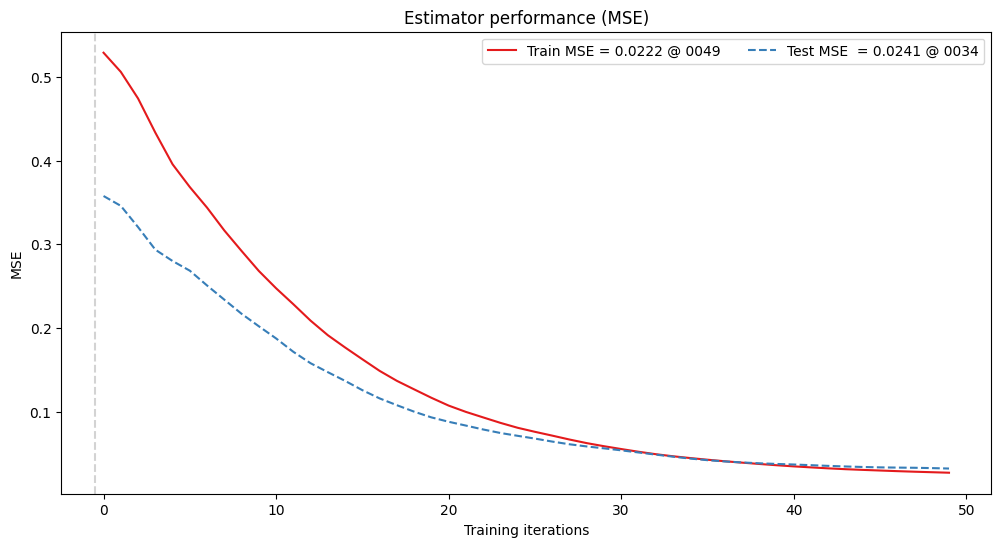

In [46]:
### Plot MSE trainnig and testing scores
train_label = f'Train MSE = {nnp.round(train_min_mse, 5):05.4f} @ {train_min_mse_iter:04d}'
test_label  = f'Test MSE  = {nnp.round(test_min_mse, 5):05.4f} @ {test_min_mse_iter:04d}'
multi_plot_series(
    [train_mse_hist, test_mse_hist], X_list=[0, 0], labels=[train_label, test_label], 
    lines=['solid', 'dashed'], # colors=None, markers=None, marker_colors=None,
    rcParams=(12, 6), xlabel='Training iterations', ylabel='MSE',
    legend_cols=2, smooth_weight=0.9, title='Estimator performance (MSE)'
)

### Plot R2 performance

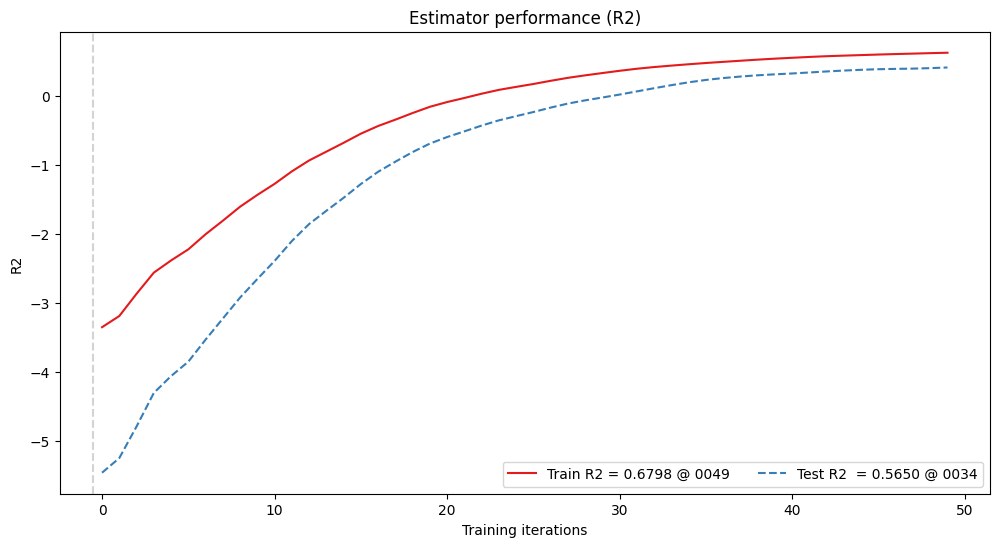

In [47]:
### Plot R2 trainnig and testing scores
train_label = f'Train R2 = {nnp.round(train_max_r2, 5):05.4f} @ {train_max_r2_iter:04d}'
test_label  = f'Test R2  = {nnp.round(test_max_r2, 5):05.4f} @ {test_max_r2_iter:04d}'
multi_plot_series(
    [train_r2_hist, test_r2_hist], X_list=[0, 0], labels=[train_label, test_label], 
    lines=['solid', 'dashed'], # colors=None, markers=None, marker_colors=None,
    rcParams=(12, 6), xlabel='Training iterations', ylabel='R2',
    legend_cols=2, smooth_weight=0.9, title='Estimator performance (R2)'
)

### Plot residuals of the expected vs predicted data
<font color="LightCoral">Task 5. Create a plot of residuals for training and test predictions.</font>

- <font color="LightCoral">Use the best model's parameters to derive predictions for all data.</font>
- <font color="LightCoral">Note that the "best" is based on the minimum MSE test score.</font>
- <font color="LightCoral">Show all results in the original data units of x, y and z axes.</font>
- <font color="LightCoral">Calculate residuals as a percentage of maximum expected values:</font>
  - <font color="LightCoral">Training residuals as a difference between true training z values <strong><em>zt_tr</em></strong> and their prediction <strong><em>z_tr</em></strong>, resulting in <strong><em>dz_tr</em></strong>.</font>
  - <font color="LightCoral">Testing residuals as a difference between true test z values <strong><em>zt_ts</em></strong> and their prediction <strong><em>z_ts</em></strong>, resulting in <strong><em>dz_ts</em></strong>.</font>

In [48]:
### Calculate residuals in the original units (dz=expected-predicted)
best_params = hist_params[test_min_mse_iter]
best_iter = int(test_min_mse_iter)
# Find the predictions for training and test data
y_pred_tr = np.array([qlinear_model(best_params, x) for x in X_train_tens])
y_pred_ts = np.array([qlinear_model(best_params, x) for x in X_test_tens])
# Rescale all data to the original units
x_tr_orig = X_scaler.inverse_transform(X_train)
x_ts_orig = X_scaler.inverse_transform(X_test)

#True values of Train and Test
zt_tr = y_scaler.inverse_transform(y_train).flatten()
zt_ts = y_scaler.inverse_transform(y_test).flatten()

#Train and Test prediction
z_tr = y_scaler.inverse_transform(np.array(y_pred_tr).reshape(-1, 1)).flatten()
z_ts = y_scaler.inverse_transform(np.array(y_pred_ts).reshape(-1, 1)).flatten()

# Calculate residuals (true-predicted) normalised to the range of values
dz_ts = zt_ts - z_ts
dz_tr = zt_tr - z_tr

print(f"Residues successfully calculated ({best_iter}):")
print(f" - Shape: X_train = {x_tr_orig.shape}, dz_train = {dz_tr.shape}")
print(f" - Shape: X_test = {x_ts_orig.shape}, dz_test = {dz_ts.shape}")
print(f" - Train: Mean = {np.mean(dz_tr):.4f}, Standard Deviation = {np.std(dz_tr):.4f}")
print(f" - Test: Mean = {np.mean(dz_ts):.4f}, Standard Deviation = {np.std(dz_ts):.4f}")

Residues successfully calculated (34):
 - Shape: X_train = (67, 2), dz_train = (67,)
 - Shape: X_test = (33, 2), dz_test = (33,)
 - Train: Mean = 19.6173, Standard Deviation = 63.2768
 - Test: Mean = 18.6804, Standard Deviation = 61.9154


In [49]:
### Plot residuals
import plotly.graph_objects as go

# Crear figura 3D interactiva
fig = go.Figure()

# Train points
fig.add_trace(go.Scatter3d(
    x=x_tr_orig[:, 0],
    y=x_tr_orig[:, 1],
    z=dz_tr.flatten(),
    mode='markers',
    name='Train Residuals',
    marker=dict(size=4, color='CornflowerBlue', opacity=0.8, symbol='circle')
))

# Test points
fig.add_trace(go.Scatter3d(
    x=x_ts_orig[:, 0],
    y=x_ts_orig[:, 1],
    z=dz_ts.flatten(),
    mode='markers',
    name='Test Residuals',
    marker=dict(size=5, color='Crimson', opacity=0.9, symbol='diamond')
))

# 3. Configuración del diseño
mrg = dict(l=50, r=50, b=50, t=50, pad=10)
fig.update_layout(
    title='Interactive 3D Residuals Plot (Expected - Predicted)',
    scene=dict(
        xaxis_title='Feature x',
        yaxis_title='Feature y',
        zaxis_title='Residual dz'
    ),
    width=700,
    height=600,
    margin=mrg,
    paper_bgcolor='whitesmoke',
    legend=dict(x=0.05, y=0.95)
)

fig.show()


**Residuals chart at the start (initial model)** (delete it after generating your charts)

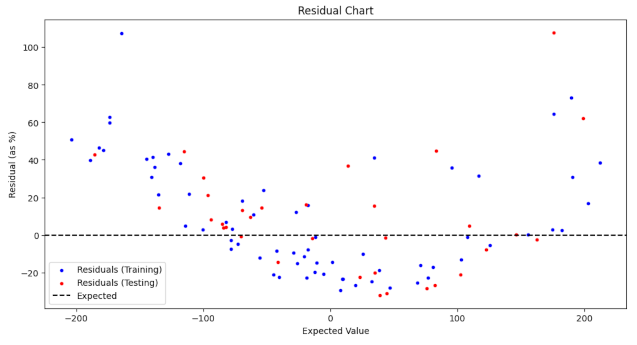

---

## <font color="blue">Challenge task:</font><br>Apply your model to the Swiss Roll data set 2 (in own time)

In [50]:
from sklearn.datasets import make_swiss_roll

np.random.seed(42)
data_seed = 42
n_samples = 1000 # Reduce to 300
noise = 0.2

X_raw, y_raw = make_swiss_roll(
    n_samples=n_samples,
    noise=0,
    random_state=data_seed,
    hole=False # With the hole it is harder
)

In [51]:
import plotly as ply
import plotly.express as px
import plotly.io as pio
# The following may preserve the chart on saving
# pio.renderers.default = 'jupyterlab' # or 'notebook'

# Create an interactive 3D scatter plot, of the first two columns
fig = px.scatter_3d(x=X_raw[:, 0], y=X_raw[:, 1], z=X_raw[:, 2], 
                    title='Interactive 3D Scatter Plot',
                    labels={'x': 'Feature x', 
                            'y': 'Feature y', 
                            'z': 'Feature z'},
                    color=y_raw, 
                    color_continuous_scale = ply.colors.sequential.Turbo)
mrg = dict(l = 50, r = 50, b = 50, t = 50, pad = 10)
fig.update_traces(marker=dict(size=3, symbol='circle'))
fig.update_layout(width=600, height=600, margin = mrg, paper_bgcolor = 'whitesmoke')
fig.show()

In [52]:
# CHALLENGE
# Define input features (X) and target (y)
# We use the first 2 columns as X and the 3rd column as Z (target)
X_sr = X_raw[:, :2]
y_sr = X_raw[:, 2].reshape(-1, 1)

# Scale the data to the angular range [0, pi]
X_sr_scaled = X_scaler.fit_transform(X_sr)
y_sr_scaled = y_scaler.fit_transform(y_sr)

# Partition Train / Test
X_tr_sr, X_ts_sr, y_tr_sr, y_ts_sr = train_test_split(
    X_sr_scaled, y_sr_scaled, test_size=0.33, random_state=seed, shuffle=False
)

X_tr_sr_tens = qml.numpy.tensor(np.array(X_tr_sr), requires_grad=False)
y_tr_sr_tens = qml.numpy.tensor(np.array(y_tr_sr), requires_grad=False)
X_ts_sr_tens = qml.numpy.tensor(np.array(X_ts_sr), requires_grad=False)
y_ts_sr_tens = qml.numpy.tensor(np.array(y_ts_sr), requires_grad=False)

# Train the quantum model for Swiss Roll (30 epochs)
params_sr = np.random.uniform(high=np.pi, size=shape, requires_grad=True)
sr_epochs = 30
opt_sr = qml.AdamOptimizer(stepsize=0.3)

print("Training model on Swiss Roll...")
for iter in range(sr_epochs):
    params_sr, cost_sr = opt_sr.step_and_cost(
        lambda p: cost_fun(p, X_tr_sr_tens, y_tr_sr_tens), params_sr
    )
    if iter % 10 == 0 or iter == sr_epochs - 1:
        print(f"Épochs {iter:02d} | Cost MSE: {cost_sr.item():.5f}")

# Evaluate in Test
pred_ts_sr = np.array([qlinear_model(params_sr, x) for x in X_ts_sr_tens])
mse_sr = mean_squared_error(y_ts_sr_tens, pred_ts_sr)
r2_sr = r2_score(y_ts_sr_tens, pred_ts_sr)

print(f"\nFinal Results Swiss Roll:")
print(f" - MSE Test: {mse_sr:.5f}")
print(f" - R2 Test : {r2_sr:.5f}")


Training model on Swiss Roll...
Épochs 00 | Cost MSE: 0.32119
Épochs 10 | Cost MSE: 0.15375
Épochs 20 | Cost MSE: 0.14804
Épochs 29 | Cost MSE: 0.14032

Final Results Swiss Roll:
 - MSE Test: 0.13419
 - R2 Test : -0.91304


---

## Write your observations here

- Task 1: With the ‘default.qubit’ simulator, the process was very slow because it had to evaluate the circuit many times for each parameter and the gradient, but switching the simulator to ‘lightning.qubit’ made everything faster.

- Task 2: Increasing the twists makes the circuit more expressive. Increasing the number of layers and epochs improves the results but increases the computation time. The hyperparameters that had the greatest impact were the Adam optimizer and the number of epochs; using too many epochs causes oscillations, while using too few causes the model to fail to learn.

- Task 3: Increasing the margin reduces the range of angles, so the circuit has less ability to identify inputs, which increases the error.

- Task 4: The MSE error for both the test and training data decreased, demonstrating that the circuit did not overfit and learned the actual trend.

- Task 5: Most of the data points were very close to zero, demonstrating that the quantum model learned correctly.

- Task 6: Since ‘PauliZ(0)’ measures the first qubit, it produces more stable gradients and is faster. In contrast, ‘PauliZ(0) @ PauliZ(1)’ measures the tensor product of all qubits, which results in complex costs and fading gradients.

- Challenge: The MSE increased and R² decreased, demonstrating that a single-layer linear quantum circuit is not capable of performing complex curved functions.

- Reflection: In this exercise, I learned how a quantum circuit can be used to solve regression problems. I understood that classical data is fed into the circuit as the rotation angles of the qubits and that the circuit’s parameters are adjusted step by step to minimize error, just as in traditional machine learning. I also found that simulating quantum circuits on a classical processor requires a significant amount of computation time, so choosing the right simulator and the number of epochs is essential.

## Modifications (do not remove)
Under the [GPL-3.0](https://www.gnu.org/licenses/gpl-3.0.txt) license, if you perform any changes to this notebook, please list them here, adding a note with your name, contact details, date and changes to the code.

- [Jacob Cybulski](http://jacobcybulski.com) (2025, 1 April): The author of this notebook added this section to record all code changes
- [Jacob Cybulski](http://jacobcybulski.com) (2026, 2 October): Now also compatible with...<br>
  pennylane                 0.45.0<br>
  pennylane_lightning       0.45.0<br>
  torch                     2.11.0+cpu<br>
  torchaudio                2.11.0<br>
  torchvision               0.26.0+cpu<br>

## Software (Linux)

In [53]:
import os
os.system('pip list | grep -e pennylane -e torch');